# Faradaic Efficiency (FE) Analysis

This notebook calculates the **Faradaic Efficiency (FE %)** of Formic Acid Decomposition (FAD) by selecting the reaction folder and aligning GC reaction rates with in-situ electrochemical current data, following the standard report generator architecture (`reaction_report.py`).

### Electrochemical Principles:
- **Formic Acid Anodic Oxidation**: $\text{HCOOH} \rightarrow \text{CO}_2 + 2\text{H}^+ + 2\text{e}^-$ ($n=2$ electrons per $\text{CO}_2$ molecule)
- **Cathodic / Decomposition Hydrogen Generation**: $2\text{H}^+ + 2\text{e}^- \rightarrow \text{H}_2$ ($n=2$ electrons per $\text{H}_2$ molecule)
- **Faraday's Law**: 
  $$I_{\text{theo}} = \text{Rate} \left(\frac{\text{mol}}{\text{s}}\right) \times n \times F$$
  $$\text{FE}_{\text{CO}_2} (\%) = \frac{I_{\text{theo, CO}_2}}{I_{\text{measured}}} \times 100 = \frac{\text{CO}_2\ (\text{nmol/min})}{\text{Current}/2\ (\text{nmol/min})} \times 100\%$$
  $$\text{FE}_{\text{H}_2} (\%) = \frac{I_{\text{theo, H}_2}}{I_{\text{measured}}} \times 100$$
  where $F = 96,485\ \text{C/mol}$.

In [1]:
import os
import sys
from pathlib import Path
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import Patch

# Ensure project root and worker_files are on sys.path
project_root = Path.cwd().resolve()
worker_dir = project_root / "worker_files"

for p in [project_root, worker_dir]:
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import config
from worker_files.file_utils import select_folder_and_load_data
from worker_files.electronics_worker import getcstats, calculate_gc_faradaic_efficiency
from worker_files.GC_worker import calc_rxn_rates, compute_schedule_summary

print("Loaded Faradaic Efficiency modules successfully!")

Loaded Faradaic Efficiency modules successfully!


### Step 1: Select Reaction Folder & Load Data
Calls `select_folder_and_load_data()`, prompting you to choose the reaction folder just like in `reaction_report.py`. You can also specify `manual_dir` if you prefer to bypass the dialog.

In [2]:
# Option A: Set a manual directory path (e.g. r"S:\projmon\velma_formic-acid-decomposition\Data\...")
manual_dir = None

if manual_dir:
    selected_dir = Path(manual_dir)
    dfs_dictionary, pre_reaction_df, _ = select_folder_and_load_data(selected_dir=selected_dir)
else:
    dfs_dictionary, pre_reaction_df, selected_dir = select_folder_and_load_data()

if dfs_dictionary is None or selected_dir is None:
    raise RuntimeError("No folder was selected. Please re-run this cell to select a reaction folder.")

print(f"\n[OK] Selected Folder: {selected_dir.name}")
print(f"Path: {selected_dir}")
print(f"Loaded datasets: {list(dfs_dictionary.keys())}")

# Set up data and plots output directories
plots_dir = selected_dir / "plots"
data_dir = selected_dir / "data"
plots_dir.mkdir(parents=True, exist_ok=True)
data_dir.mkdir(parents=True, exist_ok=True)

# Load configuration metadata (YAML & Schedule sequence)
try:
    config.handle_yaml(selected_dir)
    print(f"[Config] Successfully loaded configuration for {selected_dir.name}")
except Exception as e:
    print(f"[Notice] Local YAML/sequence load notice ({e}). Checking project defaults...")
    # Fallback copy if files are absent in the target directory
    if not list(selected_dir.glob("*.yaml")):
        default_yaml = project_root / "reaction_meta_default.yaml"
        if default_yaml.exists():
            import shutil
            shutil.copy2(default_yaml, selected_dir / default_yaml.name)
    if not list(selected_dir.glob("*sequence*.csv")):
        default_seq = project_root / "sequence_default.csv"
        if default_seq.exists():
            import shutil
            shutil.copy2(default_seq, selected_dir / default_seq.name)
    config.handle_yaml(selected_dir)

RXN_SCHEDULE = config.RXN_SCHEDULE
TRIAL_INFO = config.TRIAL_INFO
GC_METHOD_INFO = config.GC_METHOD_INFO
SHADE_COLORS = config.SHADE_COLORS

p_reac_f = float(TRIAL_INFO.get("P reactor (psig)", 0.0))
v_box_t = float(GC_METHOD_INFO.get("Valve box T (deg C)", 100.0))

GC_df = dfs_dictionary.get("FAD_df")
raw_electronics_df = dfs_dictionary.get("electronics_df")

print(f"GC data rows: {len(GC_df) if GC_df is not None else 0}")
print(f"Electronics data rows: {len(raw_electronics_df) if raw_electronics_df is not None else 0}")

Processing 'EIS' file: eis_data_20260804 17_18_20.csv
Processing 'GC' file: FAD_every30 min_total168hr 2026-08-04 17-02-40.csv
Processing 'MFC' file: mfc_data_20260804 17_18_20.csv
Processing 'Electronics' file: raw_data_20260804 17_18_20.csv
Processing 'Temperature' file: temp_data_20260804 17_18_20.csv
Processing subfolder: [10 CV_125 C_H2_-1_1_v1]
Processing subfolder: [10 CV_125 C_H2_-1_1_v2]
Processing subfolder: [10 CV_125 C_N2_-1_1_v1]
Processing subfolder: [10 CV_125 C_N2_-1_1_v2]
Processing subfolder: [CV_1 V-s_125 C_H2_-1_1_v1]
Processing subfolder: [CV_1 V-s_125 C_H2_-1_1_v2]
Processing subfolder: [CV_1 V-s_125 C_N2_-1_1_v1]
Processing subfolder: [CV_1 V-s_125 C_N2_-1_1_v2]
Processing subfolder: [CV_1 V-s_25 C_N2_-1_1_v1]
Processing subfolder: [EIS_0 V_125 C_H2_v1]
Processing subfolder: [EIS_0 V_125 C_H2_v2]
Processing subfolder: [EIS_0 V_125 C_N2_v1]
Processing subfolder: [EIS_0 V_125 C_N2_v2]

[OK] Selected Folder: Rxn - 3 - 08.04.2026
Path: S:\projmon\velma_formic-acid-de

### Step 2: Calculate Reaction Rates & Extract Current
- `getcstats()` processes raw electronics data, assigning continuous runtime, current, and scheduled voltage windows.
- `calc_rxn_rates()` calculates molar gas rates ($\text{CO}_2$, $\text{H}_2$, $\text{CO}$) from GC peak integrations.

In [3]:
# 1. Process continuous electrochemical measurements
df_electronics = getcstats(
    df_raw=raw_electronics_df, 
    file_path=None, 
    data_dir=None, 
    save_to_data_dir=False, 
    rxn_schedule=RXN_SCHEDULE
)

# 2. Calculate GC molar production rates
rates_df = calc_rxn_rates(
    GC_df=GC_df, 
    RXN_SCHEDULE=RXN_SCHEDULE, 
    v_box_t=v_box_t, 
    p_reac_f=p_reac_f, 
    GC_METHOD_INFO=GC_METHOD_INFO
)

print("Preview of calculated reaction rates:")
preview_cols = [c for c in ["Time (hr)", "Run", "Bias (V)", "Temp_C", "CO2 (nmol/min)", "H2 (nmol/min)"] if c in rates_df.columns]
display(rates_df[preview_cols].head())

Preview of calculated reaction rates:


,Time (hr),Run,Bias (V),Temp_C,CO2 (nmol/min),H2 (nmol/min)
0,0.0,1,0.0,125.0,13.929005,189717.635668
1,0.5,1,0.0,125.0,87.977261,1504.173542
2,1.0,1,0.0,125.0,122.183553,155.928898
3,1.5,1,0.0,125.0,119.647463,135.888932
4,2.0,1,0.0,125.0,106.807100,115.300654


### Step 3: Compute Faradaic Efficiency (FE %)
`electronics_worker.calculate_gc_faradaic_efficiency()` aligns each GC sampling loop window with the corresponding potentiostat current to compute:
- `Avg Current (mA)`
- `FE_CO2 (%)`
- `FE_H2 (%)`
- `FE_Total (%)`

In [4]:
# Calculate instantaneous Faradaic Efficiency
rates_df_fe = calculate_gc_faradaic_efficiency(
    rates_df=rates_df, 
    df_electronics=df_electronics, 
    n_electrons=2, 
    gc_sampling_window_sec=60,
    baseline_rate = {'CO2':72.0, 'H2':72.0}
)

fe_summary_cols = [
    "Time (hr)", "Run", "Bias (V)", "Temp_C", "N2_sccm", 
    "Avg Current (mA)", "CO2 (nmol/min)", "H2 (nmol/min)", 
    "FE_CO2 (%)", "FE_H2 (%)", "FE_Total (%)"
]
avail_fe_cols = [c for c in fe_summary_cols if c in rates_df_fe.columns]

print("=== Instantaneous Faradaic Efficiency Data ===")
display(rates_df_fe[avail_fe_cols].head(20))

# Export rates with FE to CSV
fe_rates_path = data_dir / "faradaic_efficiency_rates.csv"
rates_df_fe.to_csv(fe_rates_path, index=False)
print(f"\n[Saved] Rates with Faradaic Efficiency saved to: {fe_rates_path}")

# Compute step-averaged summary (mean ± std)
if "Bias (V)" in rates_df_fe.columns and "Run" in rates_df_fe.columns:
    step_fe_summary = rates_df_fe.groupby(["Run", "Bias (V)", "Temp_C"], as_index=False).agg({
        "Avg Current (mA)": ["mean", "std"],
        "CO2 (nmol/min)": "mean",
        "H2 (nmol/min)": "mean",
        "FE_CO2 (%)": ["mean", "std", "min", "max"],
        "FE_H2 (%)": ["mean", "std", "min", "max"],
        "FE_Total (%)": ["mean", "std"]
    }).round(2)
    
    print("\n=== Step-Averaged Faradaic Efficiency Summary ===")
    display(step_fe_summary)
    
    step_fe_path = data_dir / "faradaic_efficiency_summary.csv"
    step_fe_summary.to_csv(step_fe_path, index=False)
    print(f"[Saved] Step summary saved to: {step_fe_path}")

=== Instantaneous Faradaic Efficiency Data ===


,Time (hr),Run,Bias (V),Temp_C,N2_sccm,Avg Current (mA),CO2 (nmol/min),H2 (nmol/min),FE_CO2 (%),FE_H2 (%),FE_Total (%)
0,0.0,1,0.0,125.0,15.0,6.478028e-04,13.929005,189717.635668,-28830.69,94153952.19,94125121.51
1,0.5,1,0.0,125.0,15.0,1.723614e-04,87.977261,1504.173542,29812.66,2672354.47,2702167.13
2,1.0,1,0.0,125.0,15.0,4.648860e-05,122.183553,155.928898,0.00,0.00,0.00
3,1.5,1,0.0,125.0,15.0,1.337343e-05,119.647463,135.888932,0.00,0.00,0.00
4,2.0,1,0.0,125.0,15.0,4.770323e-06,106.807100,115.300654,0.00,0.00,0.00
5,2.5,1,0.0,125.0,15.0,3.925730e-06,102.941363,107.170871,0.00,0.00,0.00
6,3.0,1,0.0,125.0,15.0,7.693287e-06,102.461862,103.132098,0.00,0.00,0.00
7,3.5,1,0.0,125.0,15.0,2.980464e-06,88.995690,91.125449,0.00,0.00,0.00
8,4.0,1,0.0,125.0,15.0,1.178835e-07,83.340867,80.898733,0.00,0.00,0.00
9,4.5,1,0.0,125.0,15.0,1.728325e-06,85.637355,83.469317,0.00,0.00,0.00



[Saved] Rates with Faradaic Efficiency saved to: S:\projmon\velma_formic-acid-decomposition\Data\[BA12] Device #1 IDT (50um) IG(Silica + EDMIM TFSI; 30;1, 4um)-Au (50 nm)-SiO2(20 nm) + Pt (50 nm)\Rxn - 3 - 08.04.2026\data\faradaic_efficiency_rates.csv

=== Step-Averaged Faradaic Efficiency Summary ===


Run Bias (V) Temp_C Avg Current (mA)      CO2 (nmol/min) H2 (nmol/min)  \
                                   mean  std           mean          mean   
0    1      0.0  125.0             0.00  0.0          87.90       6059.26   
1    2      0.1  125.0             0.00  0.0          62.70         57.98   
2    3      0.0  125.0             0.00  0.0          74.81         69.24   
3    4      0.2  125.0             0.01  0.0          48.29         43.40   
4    5      0.0  125.0             0.00  0.0          71.19         67.30   
5    6      0.3  125.0             0.01  0.0          40.87         36.10   
6    7      0.0  125.0             0.00  0.0          69.02         64.45   
7    8      0.4  125.0             0.01  0.0          37.58         33.43   
8    9      0.0  125.0             0.00  0.0          70.45         66.16   
9   10      0.5  125.0             0.02  0.0          37.08         33.22   
10  11      0.0  125.0             0.00  0.0          71.15         67.80   
11  12     -0.1  125.0             0.00  0.0         104.40        101.86   
12  13      0.0  125.0             0.00  0.0          76.40         73.84   
13  14     -0.2  125.0             0.01  0.0         132.44        130.92   
14  15      0.0  125.0             0.00  0.0          72.97         70.67   
15  16     -0.3  125.0             0.01  0.0         185.66        187.92   
16  17      0.0  125.0             0.00  0.0          76.64         73.85   
17  18     -0.4  125.0             0.01  0.0         273.64        280.91   
18  19      0.0  125.0             0.00  0.0          99.70         97.87   
19  20     -0.5  125.0             0.02  0.0         390.88        406.87   

   FE_CO2 (%)                                FE_H2 (%)                         \
         mean      std       min       max        mean          std       min   
0       30.69  7448.69 -28830.69  29812.66  3025822.08  16635687.46      0.00   
1    -1030.56   332.87  -1289.00      0.00    -1478.57       493.58  -2100.67   
2     2326.36  9445.50   -521.93  37743.63     1560.39      6597.97  -1306.36   
3    -1232.34   353.66  -1416.96      0.00    -1461.11       420.13  -1808.20   
4    -1421.66  5108.39 -19556.36   3450.99    -3547.32      7658.96 -24588.53   
5    -1055.59   293.90  -1181.95      0.00    -1206.20       331.68  -1402.94   
6    -1577.49  5913.36 -17858.26   8944.04    -4461.76      6966.91 -21117.70   
7     -845.08   234.38   -959.63      0.00     -941.89       256.08  -1079.76   
8     2143.47  7069.23 -11625.12  13474.42    -2837.41      5709.93 -14113.14   
9     -670.48   182.67   -734.55      0.00     -738.30       203.89   -852.81   
10    6669.42  8547.00  -9573.41  19545.02     1386.80      6617.51 -11781.79   
11    4475.08  4422.37   2239.29  21003.86     3328.46       850.53   2036.97   
12     215.33   861.31      0.00   3445.25      193.26       773.03      0.00   
13    3022.25   855.98      0.00   3391.17     2964.60       856.81      0.00   
14    1054.24  3438.52      0.00  13575.48      445.20      1221.09      0.00   
15    3705.00  1124.98      0.00   4660.84     3781.50      1141.01      0.00   
16    1461.85  7251.24 -10452.86  25186.21      710.70      7109.51 -14082.79   
17    4718.97  1574.11      0.00   5981.92     4896.05      1640.23      0.00   
18    2932.52  8403.70  -5821.41  30695.20      280.33      9669.82 -14106.92   
19    5426.97  1813.50      0.00   6899.31     5700.54      1905.34      0.00   

                FE_Total (%)               
            max         mean          std  
0   94153952.19   3025852.77  16630573.37  
1          0.00     -2509.12       806.59  
2      26272.59      3886.74     16041.01  
3          0.00     -2693.45       770.94  
4          0.00     -4968.98     11858.43  
5          0.00     -2261.79       624.00  
6       1760.26     -6039.25     12403.95  
7          0.00     -1786.97       488.48  
8       7993.07      -693.94     12098.93  
9          0.00     -1408.78       385.74

[Saved] Step summary saved to: S:\projmon\velma_formic-acid-decomposition\Data\[BA12] Device #1 IDT (50um) IG(Silica + EDMIM TFSI; 30;1, 4um)-Au (50 nm)-SiO2(20 nm) + Pt (50 nm)\Rxn - 3 - 08.04.2026\data\faradaic_efficiency_summary.csv


### Step 4: Faradaic Efficiency Plots
1. **Faradaic Efficiency vs. Time**: Traces of $\text{FE}_{\text{CO}_2}$, $\text{FE}_{\text{H}_2}$, and $\text{FE}_{\text{Total}}$ with scheduled voltage bias shading.
2. **Dual-Axis Rate Comparison**: $\text{CO}_2$ gas production rate (nmol/min) plotted alongside measured electrochemical current (mA).

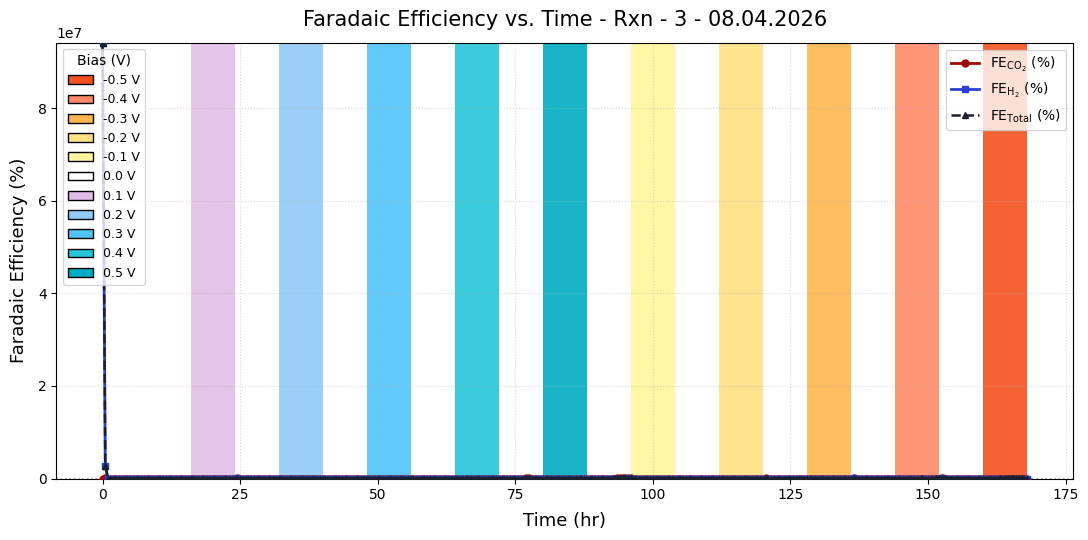

NameError: name 'CO' is not defined

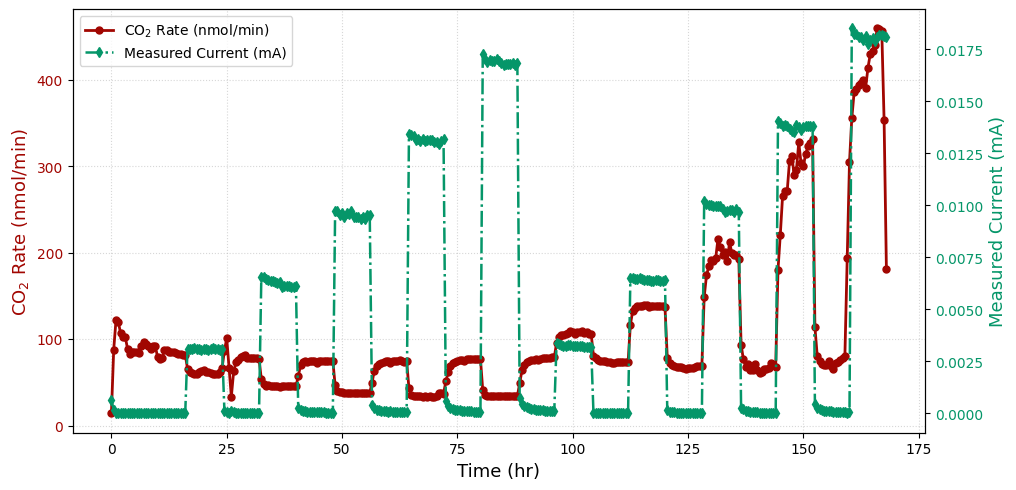

In [5]:
colors = {
    "CO2": "#A10601",     # Deep red
    "H2": "#2740CF",      # Royal blue
    "Total": "#1A202C",   # Dark slate
    "Current": "#059669"  # Green
}

# ------------------------------------------------------------
# PLOT 1: Faradaic Efficiency vs. Time with Bias Shading
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 5.5))

# Apply background bias shading
if RXN_SCHEDULE:
    for block in RXN_SCHEDULE:
        if isinstance(block, dict) and "time_window" in block:
            t0, t1 = block["time_window"]
            v = block.get("we_volt", 0.0)
            c = SHADE_COLORS.get(v, "#ffffff") if isinstance(SHADE_COLORS, dict) else "#ffffff"
            ax.axvspan(t0, t1, color=c, alpha=0.9, zorder=0, lw=0)

# Plot FE traces
t_hrs = rates_df_fe["Time (hr)"]
ax.plot(t_hrs, rates_df_fe["FE_CO2 (%)"], marker="o", color=colors["CO2"], label=r"$\text{FE}_{\text{CO}_2}$ (%)", lw=2, markersize=5, zorder=3)
ax.plot(t_hrs, rates_df_fe["FE_H2 (%)"], marker="s", color=colors["H2"], label=r"$\text{FE}_{\text{H}_2}$ (%)", lw=2, markersize=5, zorder=3)
ax.plot(t_hrs, rates_df_fe["FE_Total (%)"], marker="^", color=colors["Total"], label=r"$\text{FE}_{\text{Total}}$ (%)", lw=1.8, linestyle="--", markersize=5, zorder=3)

# Reference line at 100%
ax.axhline(100, color="gray", linestyle=":", alpha=0.7, lw=1.2, zorder=2)

ax.set_xlabel("Time (hr)", fontsize=13, labelpad=7)
ax.set_ylabel("Faradaic Efficiency (%)", fontsize=13, labelpad=7)
ax.set_title(f"Faradaic Efficiency vs. Time - {selected_dir.name}", fontsize=15, pad=12)

max_fe = rates_df_fe["FE_Total (%)"].max() if not rates_df_fe.empty else 100
ax.set_ylim(-5, max(120, max_fe + 15))
ax.grid(True, linestyle=":", alpha=0.5, zorder=1)

# Dual Legends: FE Lines & Bias Shading
lines_h, labels_h = ax.get_legend_handles_labels()
if RXN_SCHEDULE and isinstance(SHADE_COLORS, dict):
    unique_biases = sorted(list(set(b.get("we_volt", 0.0) for b in RXN_SCHEDULE if isinstance(b, dict))), key=lambda x: (isinstance(x, str), x))
    bias_patches = [Patch(facecolor=SHADE_COLORS.get(b, 'white'), edgecolor='black', label=f'{b} V' if isinstance(b, (int, float)) else str(b)) for b in unique_biases]
    leg1 = ax.legend(handles=lines_h, loc="upper right", frameon=True, fontsize=10)
    ax.add_artist(leg1)
    ax.legend(handles=bias_patches, loc="upper left", frameon=True, fontsize=9, title="Bias (V)")
else:
    ax.legend(frameon=True, fontsize=10)

plt.tight_layout()
fig.savefig(plots_dir / "Faradaic_Efficiency_vs_Time.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# PLOT 2: Rate Comparison (CO2 Production vs Measured Current)
# ------------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(11, 5.5))

ax1.plot(t_hrs, rates_df_fe["CO2 (nmol/min)"], marker="o", color=colors["CO2"], label=r"$\text{CO}_2$ Rate (nmol/min)", lw=2, markersize=5)
ax1.set_xlabel("Time (hr)", fontsize=13)
ax1.set_ylabel(r"$\text{CO}_2$ Rate (nmol/min)", color=colors["CO2"], fontsize=13)
ax1.tick_params(axis='y', labelcolor=colors["CO2"])
ax1.grid(True, linestyle=":", alpha=0.5)

ax2 = ax1.twinx()
ax2.plot(t_hrs, rates_df_fe["Avg Current (mA)"], marker="d", color=colors["Current"], label="Measured Current (mA)", lw=1.8, linestyle="-.", markersize=5)
ax2.set_ylabel("Measured Current (mA)", color=colors["Current"], fontsize=13)
ax2.tick_params(axis='y', labelcolor=colors["Current"])

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", frameon=True, fontsize=10)
plt.title(f"$\text{CO}_2$ Production vs. Electrochemical Current - {selected_dir.name}", fontsize=14, pad=12)
plt.tight_layout()
fig.savefig(plots_dir / "CO2_Rate_vs_Current.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"All plots exported successfully to: {plots_dir}")